# Telco Customer Churn Prediction

**End-to-end machine learning portfolio: customer analysis, classification, threshold selection, and a Streamlit prototype.**

Proyek ini mengklasifikasikan status churn pelanggan berdasarkan profil, layanan, kontrak, dan tagihan. Target `Churn` dikodekan sebagai `Yes = 1` dan `No = 0`.

Tujuan demonstrasi adalah memprioritaskan pelanggan untuk tinjauan retensi. Label dataset tidak cukup untuk memvalidasi klaim prediksi churn dalam 30 hari atau horizon waktu tertentu.

**Sumber:** [Telco Customer Churn — Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).

## Ringkasan hasil yang tercatat

- 7.043 pelanggan; split stratifikasi 80/20, `random_state=42`.
- XGBoost dipilih berdasarkan average precision validasi silang; AP setelah tuning 0,6722.
- Threshold dipilih menggunakan skor out-of-fold data latih, dengan target recall minimal 80% sebagai asumsi demonstrasi.
- Evaluasi akhir: ROC-AUC **0,8478**, AP **0,6693**, precision **51,21%**, recall **79,14%** pada threshold **0,27435654401779175**.
- Aplikasi lokal telah dibuka dan menghasilkan prediksi di Mac oleh pemilik proyek. Aplikasi belum dipublikasikan.

Hasil di atas dan output eksperimen dipertahankan dari notebook asli pengguna. Penyuntingan editorial ini belum menjalankan ulang pelatihan. Hasil dapat berbeda jika data atau versi library berubah.

## 1. Lingkungan dan cara menjalankan

Jalankan sel berurutan dari atas. Untuk mereproduksi lingkungan model asal, gunakan Python 3.13 dan dependensi pada `requirements-notebook.txt` dalam repository. Di Colab/Kaggle, jika perlu memasang versi tersebut, lakukan pada awal sesi lalu restart kernel sebelum menjalankan notebook. Jangan mengubah library di tengah pelatihan.

- **Kaggle:** tambahkan dataset `blastchar/telco-customer-churn` ke input notebook; loader akan mencari CSV di `/kaggle/input`.
- **Colab:** upload CSV saat diminta, atau letakkan di direktori kerja.
- **Lokal:** simpan CSV di folder `data/` pada root proyek; buka notebook dari root atau folder `notebooks/`.

Dataset mentah tidak disertakan. Periksa ketentuan penggunaan dataset pada sumber sebelum mendistribusikannya ulang.


In [ ]:
import sys
import importlib.metadata as package_metadata
import pandas as pd
from pathlib import Path
from IPython.display import display

print("Python:", sys.version.split()[0])
for package in ["pandas", "numpy", "scikit-learn", "xgboost", "joblib", "matplotlib"]:
    try:
        print(f"{package}: {package_metadata.version(package)}")
    except package_metadata.PackageNotFoundError:
        print(f"{package}: belum terpasang; pasang dependensi sebelum melanjutkan")


## 2. Memuat data

Loader berikut mendukung Colab, Kaggle, dan notebook lokal. Jika ditemukan lebih dari satu CSV Kaggle yang cocok, tentukan `DATA_PATH` secara eksplisit agar versi data tidak tertukar.


In [ ]:
# Isi dengan path CSV jika ingin menentukan file secara eksplisit.
DATA_PATH = None
file_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

if DATA_PATH is not None:
    data_path = Path(DATA_PATH)
    if not data_path.is_file():
        raise FileNotFoundError(f"CSV tidak ditemukan: {data_path}")
else:
    local_candidates = [
        Path(file_name), Path("data") / file_name,
        Path("../data") / file_name
    ]
    data_path = next((p for p in local_candidates if p.is_file()), None)
    if data_path is None and Path("/kaggle/input").is_dir():
        matches = sorted(Path("/kaggle/input").rglob(file_name))
        if len(matches) > 1:
            raise ValueError("Beberapa CSV cocok. Isi DATA_PATH dengan file yang dipilih.")
        if matches:
            data_path = matches[0]
    if data_path is None:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(
                "Tambahkan dataset di Kaggle atau simpan CSV dalam folder data/."
            ) from None
        files.upload()
        data_path = Path(file_name)
        if not data_path.is_file():
            raise FileNotFoundError(f"Upload file bernama {file_name} atau isi DATA_PATH.")

print("Membaca:", data_path)
df = pd.read_csv(data_path)
df.head()


## 3. Pemeriksaan struktur dan kualitas data

Pemeriksaan awal mencakup ukuran, tipe kolom, label target, duplikasi, dan teks kosong. Pemeriksaan skema seluruh file dilakukan sebelum split; imputasi dan transformasi yang mempelajari distribusi data dilakukan hanya di dalam pipeline data latih.

In [3]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data dan jumlah nilai yang terisi:")
df.info()

Jumlah baris: 7043
Jumlah kolom: 21

Nama kolom:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Tipe data dan jumlah nilai yang terisi:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   Inte

In [4]:
print("Jumlah pelanggan berdasarkan status churn:")
print(df["Churn"].value_counts(dropna=False))

print("\nPersentase pelanggan berdasarkan status churn:")
print(
    df["Churn"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Jumlah pelanggan berdasarkan status churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Persentase pelanggan berdasarkan status churn:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [5]:
# 1. Ringkasan target
churn_summary = pd.DataFrame({
    "Jumlah": df["Churn"].value_counts(dropna=False),
    "Persentase (%)": (
        df["Churn"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )
})

display(churn_summary)

# 2. Periksa duplikasi
print("Baris duplikat:", df.duplicated().sum())
print("customerID duplikat:", df["customerID"].duplicated().sum())

# 3. Periksa nilai kosong dan teks yang hanya berisi spasi
text_columns = df.select_dtypes(include="object").columns

blank_counts = (
    df[text_columns]
    .apply(lambda column: column.str.strip().eq(""))
    .sum()
)

quality_summary = pd.DataFrame({
    "Nilai kosong (NaN)": df.isna().sum(),
    "Teks kosong/spasi": blank_counts.reindex(
        df.columns, fill_value=0
    )
})

display(quality_summary)

# 4. Periksa TotalCharges tanpa mengubah data asli
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

invalid_total_charges = (
    df["TotalCharges"].notna()
    & total_charges_numeric.isna()
)

print(
    "TotalCharges terisi tetapi tidak bisa dibaca sebagai angka:",
    invalid_total_charges.sum()
)

display(
    df.loc[
        invalid_total_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

,Jumlah,Persentase (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


Baris duplikat: 0
customerID duplikat: 0


,Nilai kosong (NaN),Teks kosong/spasi
customerID,0,0
gender,0,0
SeniorCitizen,0,0
Partner,0,0
Dependents,0,0
tenure,0,0
PhoneService,0,0
MultipleLines,0,0
InternetService,0,0
OnlineSecurity,0,0


TotalCharges terisi tetapi tidak bisa dibaca sebagai angka: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


### Keputusan pembersihan

Tidak ada duplikasi baris atau customerID. Sebanyak 11 nilai TotalCharges berupa spasi dan seluruhnya berasosiasi dengan tenure=0. Ini konsisten dengan kemungkinan pelanggan baru, tetapi bukan bukti bahwa total tagihannya pasti nol. Baris dipertahankan dan nilai diubah menjadi NaN. Imputasi median dilakukan dalam pipeline, bukan pada seluruh dataset.

Kelas churn berjumlah 1.869 (26,54%), sedangkan tidak churn 5.174 (73,46%). Accuracy kelas mayoritas saja tidak cukup menilai kemampuan mendeteksi churn.

In [6]:
# Buat salinan agar data asli tetap tersedia.
df_clean = df.copy()

# Rapikan spasi pada awal dan akhir teks.
text_columns = df_clean.select_dtypes(include="object").columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Ubah TotalCharges menjadi numerik.
# Teks kosong atau tidak valid akan menjadi NaN.
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Pastikan target hanya berisi label yang kita harapkan.
assert df_clean["Churn"].isin(["Yes", "No"]).all(), (
    "Ditemukan label Churn yang tidak dikenal atau kosong."
)

# Ubah target menjadi angka.
df_clean["Churn"] = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Ukuran data setelah pembersihan:", df_clean.shape)
print("Tipe TotalCharges:", df_clean["TotalCharges"].dtype)
print("TotalCharges kosong:", df_clean["TotalCharges"].isna().sum())

print("\nDistribusi target: 0 = tidak churn, 1 = churn")
print(df_clean["Churn"].value_counts().sort_index())

Ukuran data setelah pembersihan: (7043, 21)
Tipe TotalCharges: float64
TotalCharges kosong: 11

Distribusi target: 0 = tidak churn, 1 = churn
Churn
0    5174
1    1869
Name: count, dtype: int64


## 4. Memisahkan pengembangan dan pengujian

customerID dikeluarkan karena merupakan identitas pelanggan. Split stratifikasi menghasilkan 5.634 baris data latih dan 1.409 baris data uji. Data uji tidak dipakai untuk EDA, tuning, atau pemilihan threshold. Split acak ini tidak mengevaluasi generalisasi antarperiode.

In [7]:
from sklearn.model_selection import train_test_split

# Fitur: keluarkan target dan identitas pelanggan.
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"]

# 80% untuk pengembangan, 20% untuk pengujian akhir.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

split_summary = pd.DataFrame({
    "Data latih (%)": y_train.value_counts(normalize=True) * 100,
    "Data uji (%)": y_test.value_counts(normalize=True) * 100
}).sort_index().round(2)

print("\nProporsi target: 0 = tidak churn, 1 = churn")
print(split_summary.to_string())

Data latih: (5634, 19)
Data uji: (1409, 19)

Proporsi target: 0 = tidak churn, 1 = churn
       Data latih (%)  Data uji (%)
Churn                              
0               73.46         73.46
1               26.54         26.54


## 5. EDA pada data latih

Tiga pertanyaan: bagaimana churn berbeda menurut kontrak, masa berlangganan, dan tagihan bulanan? Histogram menggunakan density untuk membandingkan bentuk distribusi, bukan persentase churn pada setiap rentang.

In [8]:
import matplotlib.pyplot as plt

# Gabungkan fitur dan target data latih berdasarkan indeks.
eda_train = X_train.copy()
eda_train["Churn"] = y_train

print("Ukuran data EDA:", eda_train.shape)

Ukuran data EDA: (5634, 20)


                Jumlah_pelanggan  Jumlah_churn  Tingkat_churn (%)
Contract                                                         
Month-to-month              3102          1326              42.75
One year                    1173           130              11.08
Two year                    1359            39               2.87


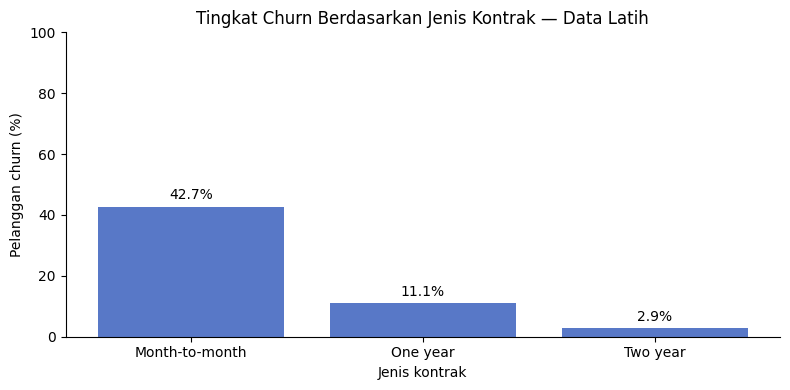

In [9]:
contract_summary = (
    eda_train
    .groupby("Contract")["Churn"]
    .agg(
        Jumlah_pelanggan="size",
        Jumlah_churn="sum",
        Tingkat_churn="mean"
    )
)

contract_summary["Tingkat_churn (%)"] = (
    contract_summary.pop("Tingkat_churn") * 100
)

contract_summary = contract_summary.sort_values(
    "Tingkat_churn (%)",
    ascending=False
)

print(contract_summary.round(2).to_string())

# Visualisasi
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    contract_summary.index,
    contract_summary["Tingkat_churn (%)"],
    color="#5878C7"
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Tingkat Churn Berdasarkan Jenis Kontrak — Data Latih")
ax.set_xlabel("Jenis kontrak")
ax.set_ylabel("Pelanggan churn (%)")
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

            tenure        MonthlyCharges       
              mean median           mean median
Churn                                          
Tidak churn  37.59   38.0          61.34  64.40
Churn        18.36   10.0          74.86  79.95


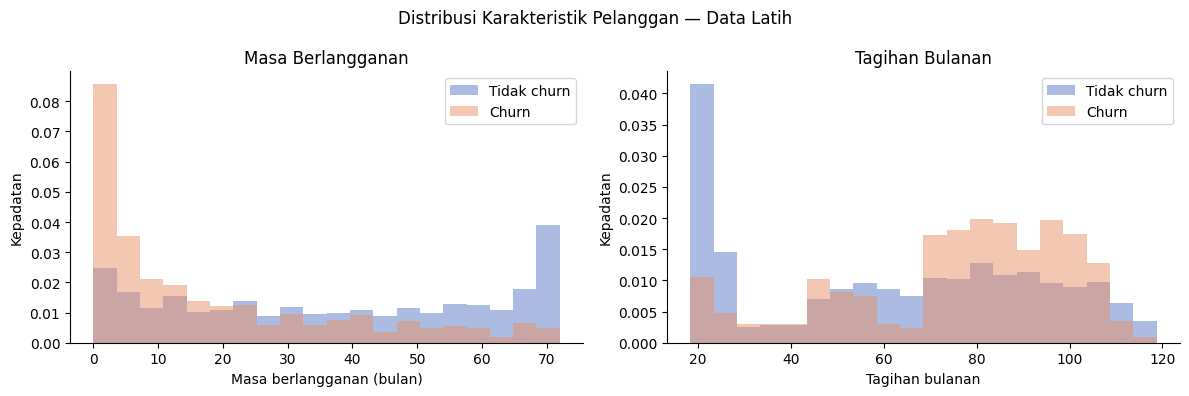

In [10]:
# Ringkasan numerik menurut status churn.
numeric_summary = (
    eda_train
    .groupby("Churn")[["tenure", "MonthlyCharges"]]
    .agg(["mean", "median"])
    .rename(index={0: "Tidak churn", 1: "Churn"})
    .round(2)
)

print(numeric_summary.to_string())

# Bandingkan distribusi menggunakan histogram.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_settings = [
    ("tenure", "Masa Berlangganan", "Masa berlangganan (bulan)"),
    ("MonthlyCharges", "Tagihan Bulanan", "Tagihan bulanan")
]

for ax, (column, title, xlabel) in zip(axes, plot_settings):
    # Gunakan batas bin yang sama untuk kedua kelompok.
    bins = 20
    value_range = (
        eda_train[column].min(),
        eda_train[column].max()
    )

    for target, label, color in [
        (0, "Tidak churn", "#5878C7"),
        (1, "Churn", "#E79367")
    ]:
        ax.hist(
            eda_train.loc[eda_train["Churn"] == target, column],
            bins=bins,
            range=value_range,
            density=True,
            alpha=0.5,
            label=label,
            color=color
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Kepadatan")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Distribusi Karakteristik Pelanggan — Data Latih")
plt.tight_layout()
plt.show()

### Temuan EDA

| Aspek | Temuan data latih |
|---|---|
| Kontrak | Churn bulanan 42,75%; satu tahun 11,08%; dua tahun 2,87% |
| Tenure | Median kelompok churn 10 bulan; tidak churn 38 bulan |
| MonthlyCharges | Median kelompok churn 79,95; tidak churn 64,40 |

Pola ini menunjukkan asosiasi. Tidak dapat disimpulkan bahwa mengubah kontrak atau tagihan otomatis akan mencegah churn.

## 6. Pipeline preprocessing

Numerik: tenure, MonthlyCharges, TotalCharges; imputasi median dan standardisasi. Kategorikal: 16 fitur termasuk SeniorCitizen; imputasi modus dan one-hot encoding dengan pengabaian kategori baru. Pipeline memastikan imputasi, skala, dan kategori dipelajari ulang pada setiap fold pelatihan.

Ini menggunakan fitur asli yang dibersihkan dan pengodean fitur. Rekayasa fitur turunan belum dilakukan; jangan mengklaim eksperimen fitur yang tidak dikerjakan.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# SeniorCitizen berisi kode kategori 0/1.
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Fitur numerik:", numeric_features)
print("Jumlah fitur kategorikal:", len(categorical_features))

Fitur numerik: ['tenure', 'MonthlyCharges', 'TotalCharges']
Jumlah fitur kategorikal: 16


## 7. Baseline dan Logistic Regression

Dummy Classifier memberi patokan kelas mayoritas; Logistic Regression menjadi model awal yang sederhana. Kelas positif adalah churn=1. Precision/recall/F1 di tahap ini memakai threshold default. Average precision (AP) dipilih sebagai kriteria utama pengembangan; AP bukan luas PR dengan integrasi trapezoidal.

In [12]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

models = {
    "Dummy Classifier": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])
}

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC_AUC": "roc_auc",
    "Average_Precision": "average_precision"
}

results = []

for name, pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in scoring:
        fold_scores = scores[f"test_{metric}"]
        row[metric] = fold_scores.mean()
        row[f"{metric}_SD"] = fold_scores.std()

    results.append(row)

cv_results = pd.DataFrame(results).set_index("Model")

print("RATA-RATA SKOR VALIDASI SILANG")
print(cv_results[list(scoring)].round(4).to_string())

print("\nSTANDAR DEVIASI ANTAR-FOLD")
print(
    cv_results[
        [f"{metric}_SD" for metric in scoring]
    ].round(4).to_string()
)

RATA-RATA SKOR VALIDASI SILANG
                     Accuracy  Precision  Recall     F1  ROC_AUC  Average_Precision
Model                                                                              
Dummy Classifier       0.7346     0.0000  0.0000  0.000   0.5000             0.2654
Logistic Regression    0.8026     0.6547  0.5431  0.593   0.8461             0.6614

STANDAR DEVIASI ANTAR-FOLD
                     Accuracy_SD  Precision_SD  Recall_SD   F1_SD  ROC_AUC_SD  Average_Precision_SD
Model                                                                                              
Dummy Classifier          0.0001         0.000     0.0000  0.0000      0.0000                0.0001
Logistic Regression       0.0120         0.028     0.0411  0.0298      0.0125                0.0193


## 8. Random Forest dan XGBoost

Perbandingan menggunakan split CV dan metrik yang sama. Parameter awal dipilih untuk demonstrasi, bukan konfigurasi optimal. CPU cukup untuk skala eksperimen ini. n_jobs=1 di model pohon menghindari paralelisasi bertingkat ketika CV berjalan paralel.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models["Random Forest"] = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ))
])

models["XGBoost"] = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

In [16]:
new_results = []

for name in ["Random Forest", "XGBoost"]:
    print(f"Memvalidasi {name}...")

    scores = cross_validate(
        models[name],
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in scoring:
        fold_scores = scores[f"test_{metric}"]
        row[metric] = fold_scores.mean()
        row[f"{metric}_SD"] = fold_scores.std()

    new_results.append(row)

new_cv_results = pd.DataFrame(new_results).set_index("Model")

# Ganti hasil model tambahan jika sel dijalankan ulang.
cv_results = pd.concat([
    cv_results.drop(
        index=new_cv_results.index,
        errors="ignore"
    ),
    new_cv_results
])

comparison = cv_results[list(scoring)].sort_values(
    "Average_Precision",
    ascending=False
)

print("\nPERBANDINGAN MODEL — VALIDASI SILANG")
print(comparison.round(4).to_string())

Memvalidasi Random Forest...
Memvalidasi XGBoost...

PERBANDINGAN MODEL — VALIDASI SILANG
                     Accuracy  Precision  Recall      F1  ROC_AUC  Average_Precision
Model                                                                               
XGBoost                0.8044     0.6676  0.5237  0.5865   0.8470             0.6681
Logistic Regression    0.8026     0.6547  0.5431  0.5930   0.8461             0.6614
Random Forest          0.7854     0.6247  0.4816  0.5434   0.8204             0.6106
Dummy Classifier       0.7346     0.0000  0.0000  0.0000   0.5000             0.2654


### Interpretasi perbandingan awal

AP XGBoost 0,6681, Logistic Regression 0,6614, Random Forest 0,6106. Logistic Regression memiliki recall dan F1 awal lebih tinggi daripada XGBoost. Selisih AP kecil dan tidak diuji signifikansinya; tidak ada dasar menyebut XGBoost unggul secara universal.

## 9. Tuning ringan

Masing-masing model mendapat delapan kombinasi parameter, dievaluasi dengan 5-fold CV. XGBoost mencapai AP CV 0,6722; Logistic Regression tetap 0,6614. Skor terbaik hasil pencarian cenderung optimistis karena dipakai untuk memilih konfigurasi.

In [17]:
from sklearn.model_selection import GridSearchCV

parameter_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "XGBoost": {
        "model__max_depth": [2, 3],
        "model__n_estimators": [150, 300],
        "model__min_child_weight": [1, 5]
    }
}

searches = {}
tuning_rows = []

for name, parameters in parameter_grids.items():
    print(f"\nTuning {name}...")

    search = GridSearchCV(
        estimator=clone(models[name]),
        param_grid=parameters,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    search.fit(X_train, y_train)
    searches[name] = search

    best_index = search.best_index_

    tuning_rows.append({
        "Model": name,
        "CV_AP_sebelum": cv_results.loc[
            name, "Average_Precision"
        ],
        "CV_AP_setelah": search.best_score_,
        "SD_AP_setelah": search.cv_results_[
            "std_test_score"
        ][best_index]
    })

    print("Parameter terbaik:", search.best_params_)
    print(f"Average precision CV: {search.best_score_:.4f}")

tuning_summary = pd.DataFrame(tuning_rows).set_index("Model")

print("\nHASIL TUNING")
print(tuning_summary.round(4).to_string())


Tuning Logistic Regression...
Parameter terbaik: {'model__C': 1, 'model__class_weight': None}
Average precision CV: 0.6614

Tuning XGBoost...
Parameter terbaik: {'model__max_depth': 2, 'model__min_child_weight': 1, 'model__n_estimators': 300}
Average precision CV: 0.6722

HASIL TUNING
                     CV_AP_sebelum  CV_AP_setelah  SD_AP_setelah
Model                                                           
Logistic Regression         0.6614         0.6614         0.0193
XGBoost                     0.6681         0.6722         0.0196


## 10. Pemilihan threshold dari data pengembangan

XGBoost dipilih berdasarkan AP CV tertinggi. Tujuan demonstrasi ditetapkan sebagai precision OOF tertinggi dengan recall minimal 80%; ini bukan target bisnis terverifikasi.

Setiap skor OOF berasal dari model yang tidak dilatih pada baris tersebut. Namun, hyperparameter telah dipilih menggunakan seluruh data pengembangan. Karena itu, skor ini bukan estimasi independen tanpa bias seleksi dan bukan nested CV. Evaluasi akhir tetap memakai data uji yang disisihkan.

In [18]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

selected_model_name = "XGBoost"

# Model ini sudah dilatih ulang pada seluruh data latih oleh GridSearchCV.
final_model = searches[selected_model_name].best_estimator_

# Clone akan menghapus status pelatihan sebelum validasi silang.
oof_scores = cross_val_predict(
    clone(final_model),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Jumlah skor out-of-fold:", len(oof_scores))

Jumlah skor out-of-fold: 5634


In [19]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(y_train, oof_scores)
)

# Elemen precision dan recall terakhir tidak memiliki threshold pasangan.
threshold_candidates = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_values[:-1],
    "Recall": recall_values[:-1]
})

target_recall = 0.80

eligible = threshold_candidates[
    threshold_candidates["Recall"] >= target_recall
]

best_threshold_row = (
    eligible
    .sort_values(
        ["Precision", "Recall", "Threshold"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

selected_threshold = float(best_threshold_row["Threshold"])

print("MODEL:", selected_model_name)
print(f"Threshold terpilih: {selected_threshold:.6f}")
print(f"Precision OOF: {best_threshold_row['Precision']:.4f}")
print(f"Recall OOF: {best_threshold_row['Recall']:.4f}")

MODEL: XGBoost
Threshold terpilih: 0.274357
Precision OOF: 0.5299
Recall OOF: 0.8000


In [20]:
threshold_rows = []

for label, threshold in [
    ("Default", 0.5),
    ("Target recall 80%", selected_threshold)
]:
    predictions = (oof_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "Pengaturan": label,
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Ditandai_berisiko (%)": predictions.mean() * 100
    })

threshold_comparison = pd.DataFrame(threshold_rows)

print(threshold_comparison.round(4).to_string(index=False))

       Pengaturan  Threshold  Precision  Recall     F1   TP   FP  FN   TN  Ditandai_berisiko (%)
          Default     0.5000     0.6669  0.5291 0.5901  791  395 704 3744                21.0508
Target recall 80%     0.2744     0.5299  0.8000 0.6375 1196 1061 299 3078                40.0603


### Dampak threshold pada OOF

Threshold 0,27435654401779175 meningkatkan churn terdeteksi dari 791 menjadi 1.196, disertai kenaikan alarm keliru dari 395 menjadi 1.061. Target recall 80% membutuhkan penandaan sekitar 40,06% pelanggan data pengembangan. Model dan threshold kemudian ditetapkan sebelum melihat hasil uji.

## 11. Evaluasi akhir pada data uji

Perbandingan default 0,5 dan threshold terpilih telah direncanakan sebelum evaluasi. Hasil uji tidak digunakan untuk memilih ulang threshold atau hyperparameter. Jangan menyesuaikan keputusan setelah melihat hasil bagian ini.

EVALUASI AKHIR — DATA UJI
        Pengaturan  Threshold  Accuracy  Precision  Recall     F1  TP  FP  FN  TN  Ditandai_berisiko (%)
           Default     0.5000    0.8119     0.6886  0.5321 0.6003 199  90 175 945                 20.511
Threshold terpilih     0.2744    0.7445     0.5121  0.7914 0.6218 296 282  78 753                 41.022

ROC-AUC data uji: 0.8478
Average precision data uji: 0.6693


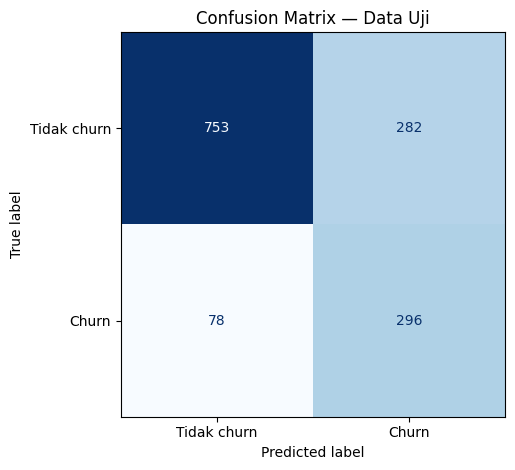

In [21]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

# final_model sudah dilatih pada seluruh X_train oleh GridSearchCV.
# Gunakan nilai threshold asli, bukan angka tampilan yang dibulatkan.
test_scores = final_model.predict_proba(X_test)[:, 1]

test_rows = []

for label, threshold in [
    ("Default", 0.5),
    ("Threshold terpilih", selected_threshold)
]:
    predictions = (test_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    test_rows.append({
        "Pengaturan": label,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Ditandai_berisiko (%)": predictions.mean() * 100
    })

test_results = pd.DataFrame(test_rows)

print("EVALUASI AKHIR — DATA UJI")
print(test_results.round(4).to_string(index=False))

# Kedua metrik ini dihitung dari skor, bukan label threshold.
test_roc_auc = roc_auc_score(y_test, test_scores)
test_ap = average_precision_score(y_test, test_scores)

print(f"\nROC-AUC data uji: {test_roc_auc:.4f}")
print(f"Average precision data uji: {test_ap:.4f}")

# Confusion matrix untuk threshold yang telah dipilih.
test_predictions = (
    test_scores >= selected_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Tidak churn", "Churn"],
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix — Data Uji")
plt.tight_layout()
plt.show()

### Kesimpulan evaluasi

| Pengaturan | Accuracy | Precision | Recall | F1 | TP | FP | FN | TN |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Default 0,5 | 0,8119 | 0,6886 | 0,5321 | 0,6003 | 199 | 90 | 175 | 945 |
| Threshold terpilih | 0,7445 | 0,5121 | 0,7914 | 0,6218 | 296 | 282 | 78 | 753 |

ROC-AUC = 0,8478 dan AP = 0,6693. Threshold terpilih mendeteksi 97 churn tambahan dengan 192 alarm keliru tambahan. Sebanyak 578 dari 1.409 pelanggan (41,02%) ditandai; 296 di antaranya benar-benar churn.

Penurunan accuracy merupakan konsekuensi keputusan untuk mendeteksi lebih banyak churn. Recall uji 79,14% mendekati target pengembangan, tetapi target 80% tidak dijamin pada data baru. Belum ada data biaya atau uji intervensi yang membuktikan manfaat ekonomi.

## 12. Menyimpan pipeline dan metadata

Pipeline yang disimpan tetap model yang dilatih pada data latih dan dievaluasi pada data uji, bukan hasil pelatihan ulang pada semua data. Simpan threshold dengan presisi aslinya. Muat file joblib hanya dari sumber tepercaya.


In [22]:
from pathlib import Path
import json
import joblib
import platform
import sklearn
import xgboost

output_dir = Path("churn_artifacts")
output_dir.mkdir(exist_ok=True)

# Simpan seluruh preprocessing dan model dalam satu paket.
bundle = {
    "pipeline": final_model,
    "threshold": float(selected_threshold),
    "feature_names": X_train.columns.tolist(),
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "category_options": {
        column: sorted(X_train[column].dropna().unique().tolist())
        for column in categorical_features
    }
}

model_path = output_dir / "churn_model.joblib"
joblib.dump(bundle, model_path)

# Simpan hasil evaluasi.
test_results.to_csv(
    output_dir / "test_results.csv",
    index=False
)

metadata = {
    "model": selected_model_name,
    "threshold": float(selected_threshold),
    "threshold_selection": (
        "Highest OOF precision subject to recall >= 0.80"
    ),
    "test_roc_auc": float(test_roc_auc),
    "test_average_precision": float(test_ap),
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "joblib": joblib.__version__
    }
}

with open(output_dir / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

# Verifikasi model yang dimuat ulang menghasilkan skor yang sama.
loaded_bundle = joblib.load(model_path)

np.testing.assert_allclose(
    loaded_bundle["pipeline"].predict_proba(
        X_test.iloc[:10]
    )[:, 1],
    test_scores[:10]
)

print("Pipeline berhasil disimpan dan dimuat ulang.")
print("Threshold:", loaded_bundle["threshold"])

Pipeline berhasil disimpan dan dimuat ulang.
Threshold: 0.27435654401779175


## 13. Paket artefak

ZIP dibuat pada direktori kerja. Unduhan otomatis hanya dilakukan di Colab; di Kaggle/lokal gunakan tautan file berikut atau panel file/output notebook.

In [ ]:
import shutil
from IPython.display import FileLink

archive_path = shutil.make_archive(
    "churn_artifacts", "zip", root_dir=".", base_dir="churn_artifacts"
)
display(FileLink(archive_path))
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(archive_path)


## 14. Batasan dan pengembangan berikutnya

1. Ini merupakan studi pada dataset contoh. Generalisasi ke perusahaan dan periode baru belum diuji; belum ada horizon prediksi masa depan yang divalidasi.
2. Tidak ada evaluasi kalibrasi probabilitas; keluaran aplikasi disebut skor prediksi, bukan probabilitas yang telah terkalibrasi.
3. Hyperparameter dan threshold menggunakan data pengembangan yang sama. Evaluasi independen yang dilaporkan adalah holdout akhir; interval ketidakpastian holdout belum dihitung.
4. Kapasitas tindak lanjut, biaya alarm keliru, biaya kehilangan pelanggan, dan efektivitas penawaran belum dimodelkan. Target recall 80% adalah asumsi latihan.
5. Model menggunakan demografi. Evaluasi fairness dan kelayakan penggunaan fitur untuk aplikasi nyata belum dilakukan.
6. Pentingnya fitur model belum dianalisis; EDA tidak membuktikan kontribusi independen ataupun kausalitas.
7. Prototipe telah menghasilkan prediksi lokal di Mac, tetapi belum diterapkan ke hosting publik atau dipantau terhadap perubahan distribusi data.

Pengembangan berikutnya dapat menguji kalibrasi, validasi temporal jika timestamp tersedia, analisis kapasitas/kos, interpretasi model, dan pengujian fairness. Eksperimen tersebut merupakan rencana, bukan pekerjaan yang sudah diselesaikan.

## Referensi teknis

- [Dataset Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- [scikit-learn: pipelines](https://scikit-learn.org/stable/modules/compose.html)
- [scikit-learn: model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [XGBoost documentation](https://xgboost.readthedocs.io/)

Proyek dikembangkan secara bertahap dengan bantuan AI untuk pembelajaran, penulisan kode, dan dokumentasi. Hasil numerik berasal dari eksekusi notebook pengguna; penjelasan metodologi perlu dipahami dan diverifikasi oleh pemilik portofolio.
